# LAB 3 – Bài 5 (Trang 29): Gom nhóm khối u lành tính / ác tính (Breast Cancer Wisconsin – Diagnostic)

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [2]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             silhouette_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")

Trang Kim Đạt – 6451071018


## 1. Đọc dữ liệu
File `wdbc.data` gồm: ID, chẩn đoán (M = ác tính, B = lành tính) và 30 thuộc tính (mean, standard error, worst của 10 đặc trưng tế bào).

In [3]:
print(f"{HO_TEN} – {MSSV}")
dac_trung = ["radius", "texture", "perimeter", "area", "smoothness",
             "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
cot = ["id", "diagnosis"] + [f"{d}_{h}" for h in ("mean", "se", "worst") for d in dac_trung]
df = pd.read_csv("breast+cancer+wisconsin+diagnostic/wdbc.data", header=None, names=cot)
print("Kích thước:", df.shape)
print("Giá trị thiếu:", int(df.isnull().sum().sum()))
print(df["diagnosis"].value_counts().rename({"B": "B (lành tính)", "M": "M (ác tính)"}))
df.head()

Trang Kim Đạt – 6451071018
Kích thước: (569, 32)
Giá trị thiếu: 0
diagnosis
B (lành tính)    357
M (ác tính)      212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Tiền xử lý
Bỏ cột `id`, giữ nhãn `diagnosis` **chỉ để đánh giá**. Chuẩn hóa z-score các thuộc tính vì k-Means dựa trên khoảng cách và các thuộc tính (vd. `area` ~ hàng trăm/nghìn, `smoothness` ~ 0,1) có thang đo rất khác nhau.

In [4]:
print(f"{HO_TEN} – {MSSV}")
X = df.drop(columns=["id", "diagnosis"])
y_that = (df["diagnosis"] == "M").astype(int).values   # 1 = ác tính, 0 = lành tính
X_chuan_hoa = StandardScaler().fit_transform(X)
print(X_chuan_hoa.shape)

Trang Kim Đạt – 6451071018
(569, 30)


## 3. Gom cụm bằng k-Means (k = 2)

In [5]:
print(f"{HO_TEN} – {MSSV}")
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
cum = kmeans.fit_predict(X_chuan_hoa)

# Cụm nào là "ác tính"? -> cụm có tỷ lệ ác tính cao hơn
ty_le_ac = [y_that[cum == c].mean() for c in (0, 1)]
cum_ac_tinh = int(np.argmax(ty_le_ac))
y_pred = (cum == cum_ac_tinh).astype(int)
print("Số mẫu mỗi cụm:", np.bincount(cum))
print("Cụm được xem là ác tính:", cum_ac_tinh)
print(f"Silhouette coefficient: {silhouette_score(X_chuan_hoa, cum):.4f}")

Trang Kim Đạt – 6451071018
Số mẫu mỗi cụm: [375 194]
Cụm được xem là ác tính: 1
Silhouette coefficient: 0.3434


## 4. So sánh kết quả gom cụm với chẩn đoán thực tế

Trang Kim Đạt – 6451071018
Accuracy: 0.9051
Adjusted Rand Index: 0.6536
               precision    recall  f1-score   support

Lành tính (B)     0.9040    0.9496    0.9262       357
  Ác tính (M)     0.9072    0.8302    0.8670       212

     accuracy                         0.9051       569
    macro avg     0.9056    0.8899    0.8966       569
 weighted avg     0.9052    0.9051    0.9042       569



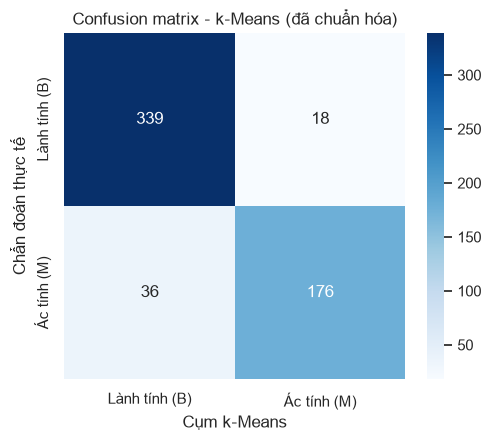

In [6]:
print(f"{HO_TEN} – {MSSV}")
ten_lop = ["Lành tính (B)", "Ác tính (M)"]
print("Accuracy:", round(accuracy_score(y_that, y_pred), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y_that, y_pred), 4))
print(classification_report(y_that, y_pred, target_names=ten_lop, digits=4))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_that, y_pred), annot=True, fmt="d", cmap="Blues", xticklabels=ten_lop, yticklabels=ten_lop)
plt.xlabel("Cụm k-Means"); plt.ylabel("Chẩn đoán thực tế"); plt.title("Confusion matrix - k-Means (đã chuẩn hóa)")
plt.show()

## 5. Trực quan hóa bằng PCA (2 thành phần chính)

Trang Kim Đạt – 6451071018
Phương sai giải thích bởi 2 thành phần: [0.443 0.19 ] -> tổng 0.632


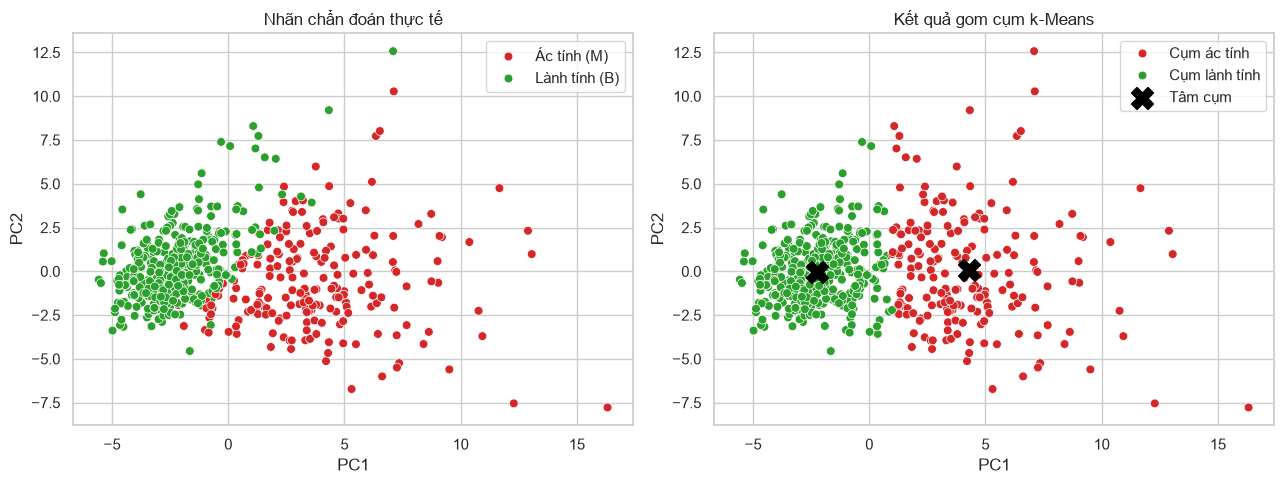

In [7]:
print(f"{HO_TEN} – {MSSV}")
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_chuan_hoa)
print("Phương sai giải thích bởi 2 thành phần:", pca.explained_variance_ratio_.round(3), "-> tổng", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=np.where(y_that == 1, "Ác tính (M)", "Lành tính (B)"),
                palette={"Ác tính (M)": "tab:red", "Lành tính (B)": "tab:green"}, ax=axes[0], s=40)
axes[0].set_title("Nhãn chẩn đoán thực tế")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=np.where(y_pred == 1, "Cụm ác tính", "Cụm lành tính"),
                palette={"Cụm ác tính": "tab:red", "Cụm lành tính": "tab:green"}, ax=axes[1], s=40)
tam = pca.transform(kmeans.cluster_centers_)
axes[1].scatter(tam[:, 0], tam[:, 1], c="black", marker="X", s=250, label="Tâm cụm")
axes[1].set_title("Kết quả gom cụm k-Means"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 6. Ảnh hưởng của việc chuẩn hóa và so sánh với gom cụm phân cấp (Agglomerative)

In [8]:
print(f"{HO_TEN} – {MSSV}")
def tom_tat(ten, cum_x):
    # gán cụm nào là ác tính theo đa số rồi tính accuracy
    ac = int(np.argmax([y_that[cum_x == c].mean() for c in (0, 1)]))
    yp = (cum_x == ac).astype(int)
    return {"Phương pháp": ten, "Accuracy": accuracy_score(y_that, yp),
            "Precision (M)": ((yp == 1) & (y_that == 1)).sum() / max((yp == 1).sum(), 1),
            "Recall (M)": ((yp == 1) & (y_that == 1)).sum() / (y_that == 1).sum(),
            "ARI": adjusted_rand_score(y_that, yp)}

cum_khong_chuan_hoa = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X.values)
cum_phan_cap = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_chuan_hoa)
pd.DataFrame([
    tom_tat("k-Means (không chuẩn hóa)", cum_khong_chuan_hoa),
    tom_tat("k-Means (chuẩn hóa z-score)", cum),
    tom_tat("Agglomerative - Ward (chuẩn hóa)", cum_phan_cap),
]).round(4)

Trang Kim Đạt – 6451071018


,Phương pháp,Accuracy,Precision (M),Recall (M),ARI
0,k-Means (không chuẩn hóa),0.8541,0.9924,0.6132,0.4914
1,k-Means (chuẩn hóa z-score),0.9051,0.9072,0.8302,0.6536
2,Agglomerative - Ward (chuẩn hóa),0.8805,0.8913,0.7736,0.5750


## 7. Nhận xét
- Sau khi chuẩn hóa, k-Means với k = 2 tách khá tốt hai nhóm khối u: phần lớn khối u lành tính và ác tính rơi vào hai cụm khác nhau (xem confusion matrix và biểu đồ PCA), dù thuật toán **không được cung cấp nhãn**.
- Một số khối u nằm ở vùng giáp ranh giữa hai nhóm trên biểu đồ PCA nên bị gom nhầm; trong bài toán y tế, các trường hợp **ác tính bị xếp vào cụm lành tính (False Negative)** là sai sót nghiêm trọng nhất nên cần xem Recall của lớp ác tính.
- Việc chuẩn hóa ảnh hưởng đáng kể: khi không chuẩn hóa, các thuộc tính có thang đo lớn như `area`, `perimeter` chi phối khoảng cách Euclide, các thuộc tính còn lại gần như không đóng góp; kết quả là Accuracy giảm (≈ 0,85 so với ≈ 0,91) và Recall của lớp ác tính chỉ ≈ 0,61 (bỏ sót nhiều khối u ác tính).
- Gom cụm phân cấp (Ward) cho kết quả thấp hơn k-Means một chút (Accuracy ≈ 0,88) nhưng cùng xu hướng, cho thấy cấu trúc hai nhóm trong dữ liệu khá rõ ràng. Gom cụm chỉ mang tính hỗ trợ khám phá; để chẩn đoán cần các mô hình phân lớp có giám sát.